# Spotify Genre Classification

### About the Dataset

This dataset is from Kaggle and contains Spotify tracks from a wide range of genres. 
The Kaggle page says 125 genres, but the file itself contains 114 genres with 1,000 tracks each, 
which gives 114,000 tracks in total. Each track has a set of audio features that describe 
how the song sounds, like how danceable, energetic or loud it is.

The data is in CSV format, which is tabular and quick to load with pandas.

Link: https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset

Credit goes to Maharshi Pandya.

##### Understanding the Audio Features

To help understand how the models separate the genres, here is a simple explanation of what each audio feature actually measures:

* **Popularity:** A score from 0 to 100 based on how many times a song has been played recently.
* **Duration_ms:** The length of the track measured in milliseconds.
* **Explicit:** A true/false (1 or 0) value showing if the song contains lyrics that are not suitable for children.
* **Danceability:** How suitable a track is for dancing based on tempo, rhythm stability, and beat strength (from 0.0 to 1.0).
* **Energy:** A measure from 0.0 to 1.0 representing intensity and activity. High energy feels fast, loud, and noisy (like heavy metal).
* **Key:** The overall key the track is in (e.g., C, C#, D) using standard pitch notation.
* **Loudness:** The overall loudness of a track in decibels (dB), usually ranging between -60 and 0 dB.
* **Mode:** The modality of a track (Major = 1, Minor = 0), which often defines if a song sounds "happy" or "sad".
* **Speechiness:** Detects the presence of spoken words. A value close to 1.0 means it is mostly talking (like a podcast or rap), while lower values mean music.
* **Acousticness:** A score from 0.0 to 1.0 showing how likely it is that the song uses acoustic instruments (like an acoustic guitar or piano) rather than electronic ones.
* **Instrumentalness:** Predicts whether a track contains no vocals. The closer to 1.0, the more likely the song has no singing at all.
* **Liveness:** Detects the presence of an audience in the recording. Higher values mean the song was probably recorded live at a concert.
* **Valence:** A measure from 0.0 to 1.0 describing the musical positiveness. High valence sounds happy/cheerful, while low valence sounds sad/angry.
* **Tempo:** The overall speed of the track measured in Beats Per Minute (BPM).
* **Time_signature:** An estimated overall time signature of a track (e.g., 3/4 or 4/4 bar). - time_signature: The number of beats within each bar of the track. (Integer)



# EXPLORATORY DATA ANALYSIS

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import scipy.stats as stats

df = pd.read_csv("../dataset/spotify.csv")


In [2]:
df.shape # Tells us the amount of instances and features in the dataset 


(114000, 21)

In [3]:
df.head(10) # checking the data and their rows

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
5,5,01MVOl9KtVTNfFiBU9I7dc,Tyrone Wells,Days I Will Remember,Days I Will Remember,58,214240,False,0.688,0.4810,...,-8.807,1,0.1050,0.2890,0.000000,0.1890,0.6660,98.017,4,acoustic
6,6,6Vc5wAMmXdKIAM7WUoEb7N,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74,229400,False,0.407,0.1470,...,-8.822,1,0.0355,0.8570,0.000003,0.0913,0.0765,141.284,3,acoustic
7,7,1EzrEOXmMH3G43AXT1y7pA,Jason Mraz,We Sing. We Dance. We Steal Things.,I'm Yours,80,242946,False,0.703,0.4440,...,-9.331,1,0.0417,0.5590,0.000000,0.0973,0.7120,150.960,4,acoustic
8,8,0IktbUcnAGrvD03AWnz3Q8,Jason Mraz;Colbie Caillat,We Sing. We Dance. We Steal Things.,Lucky,74,189613,False,0.625,0.4140,...,-8.700,1,0.0369,0.2940,0.000000,0.1510,0.6690,130.088,4,acoustic
9,9,7k9GuJYLp2AzqokyEdwEw2,Ross Copperman,Hunger,Hunger,56,205594,False,0.442,0.6320,...,-6.770,1,0.0295,0.4260,0.004190,0.0735,0.1960,78.899,4,acoustic


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

The dataset contains 114,000 rows and 21 columns. Most columns have complete data; however, the artist, album_name, and track_name columns each contain one missing value, for a total of three missing values.
The dataset includes one Boolean column, nine float columns, six integer columns, and five object (text) columns.



In [5]:
df['track_genre'].nunique()

114

Why I Reduced the Dataset
The original dataset included 114 music genres. This is too many categories for this project, especially because many genres are very similar.
With 114 genres, a random guess would only be correct about 0.9% of the time:
- 1 ÷ 114 = 0.00877
- This is about 0.88%
This also makes model results harder to understand. For example, 20% accuracy may look low, but it is still much better than random guessing.
Many of the genres also overlap. For example, pop, indie-pop, and synth-pop can have similar values for tempo, loudness, and energy. Since the model only uses numerical audio features, it may struggle to separate genres that sound or look similar in the data.
To make the project more manageable, I selected seven genres:
- classical
- heavy-metal
- hip-hop
- jazz
- reggae
- house
- techno
Most of these genres are quite different from each other. However, I included both house and techno because they are similar electronic genres. This gives the models a more realistic challenge and makes the confusion matrix more interesting to analyse. I expect some house tracks to be predicted as techno, and vice versa.
I did not include electronic as a separate genre because house and techno are already subgenres of electronic music. Including all three could create too much overlap and make the results harder to explain.
The final dataset contains 7,000 tracks: 1,000 tracks for each of the seven genres. The classes are balanced, with each genre making up 14.29% of the dataset. This means accuracy can be used fairly without worrying about class imbalance.
Finally, value_counts(normalize=True) only shows class counts as percentages. It does not scale the data. Feature scaling will be done later during preprocessing.

In [6]:
genres = ['classical', 'heavy-metal', 'hip-hop', 'jazz', 'reggae', 'house', 'techno']
df = df[df['track_genre'].isin(genres)].copy()

print(df.shape)
print(df['track_genre'].value_counts())

(7000, 21)
track_genre
classical      1000
heavy-metal    1000
hip-hop        1000
house          1000
jazz           1000
reggae         1000
techno         1000
Name: count, dtype: int64


In [7]:
df['track_genre'].shape

(7000,)

In [8]:
print(df['track_genre'].value_counts(normalize = True) * 100) # Checking if its normalized 

track_genre
classical      14.285714
heavy-metal    14.285714
hip-hop        14.285714
house          14.285714
jazz           14.285714
reggae         14.285714
techno         14.285714
Name: proportion, dtype: float64


In [9]:
df['track_genre'].nunique()

7

In [10]:
df.columns.tolist()

['Unnamed: 0',
 'track_id',
 'artists',
 'album_name',
 'track_name',
 'popularity',
 'duration_ms',
 'explicit',
 'danceability',
 'energy',
 'key',
 'loudness',
 'mode',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'time_signature',
 'track_genre']

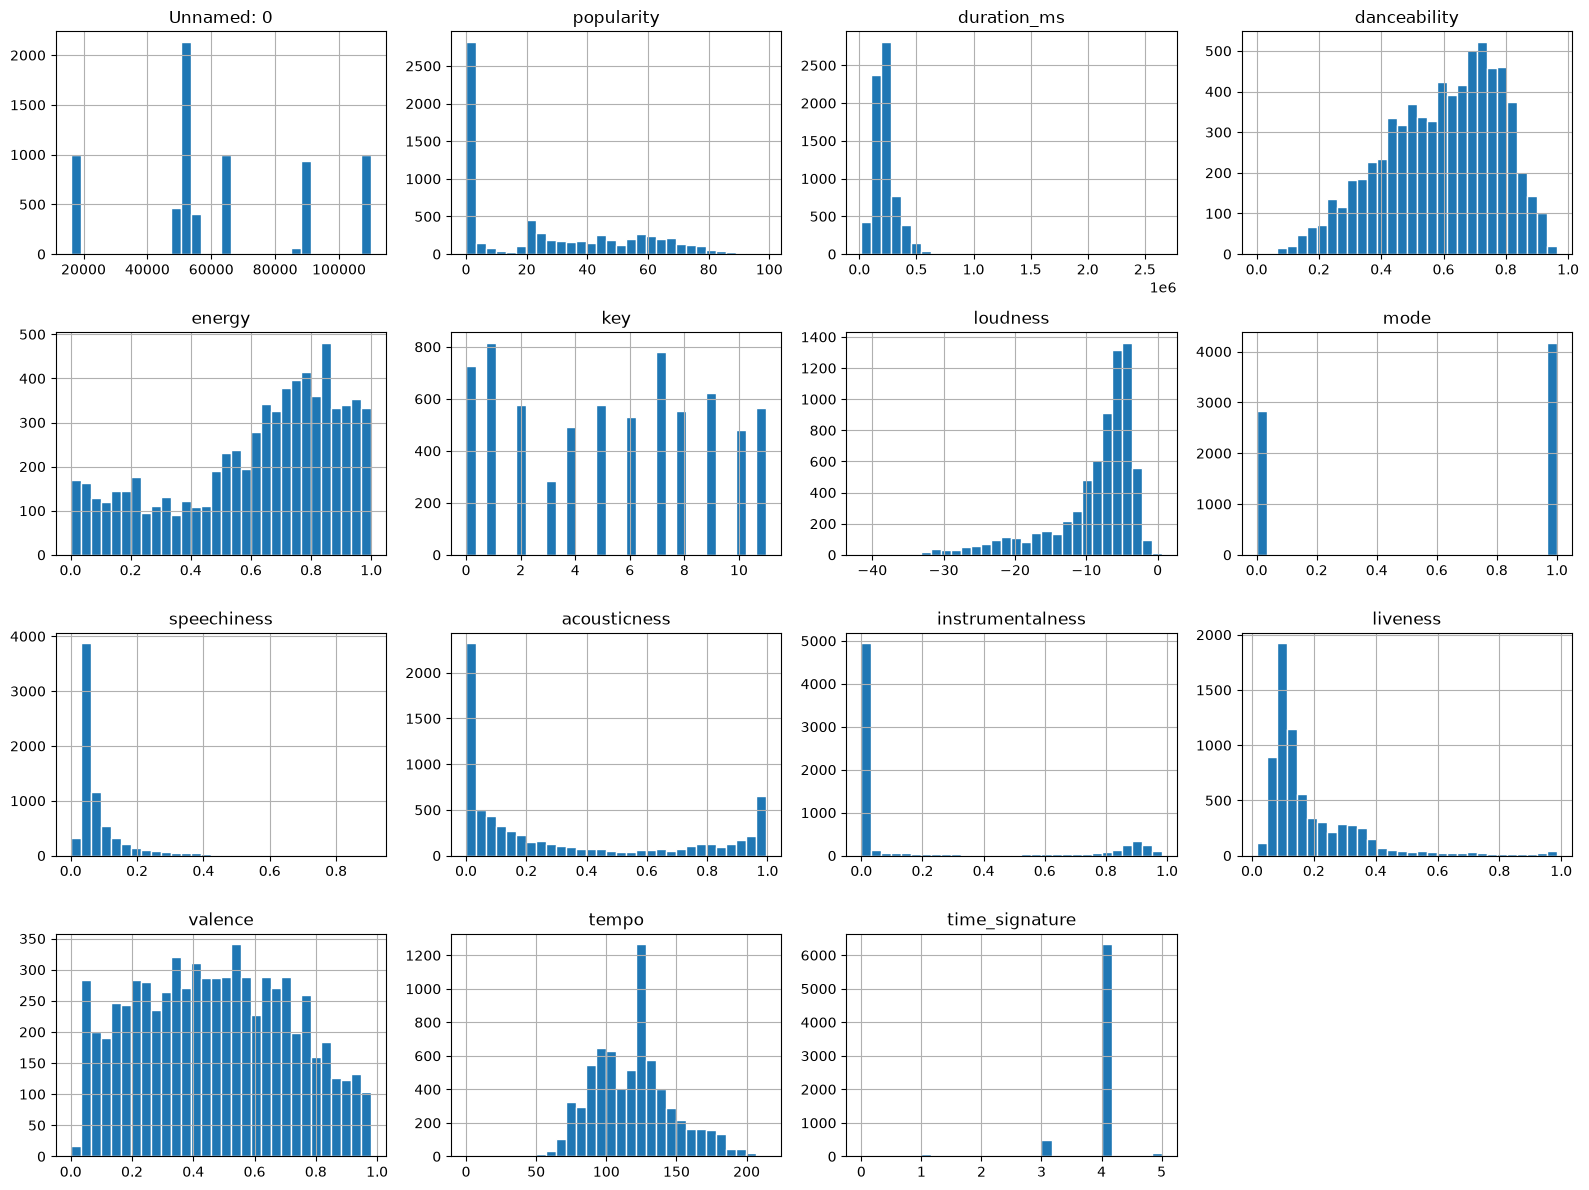

In [11]:
# all numeric audio features
numeric_cols = df.select_dtypes(include='number').columns.tolist()

df[numeric_cols].hist(bins=30, figsize=(16, 12), edgecolor='white')
plt.tight_layout()
plt.show()

# DATA PREPROCESSING

### Feature Selection: Dropping Unnecessary Columns (My Understanding)

Our **predictive label** (the target variable) is **`track_genre`**. This is the music genre we want our models to predict, so we definitely keep this column. 

However, the dataset has 21 columns in total, and many of them are just text identifiers. I decided to drop the following columns: 
* `Unnamed: 0`
* `track_id`
* `artists`
* `album_name`
* `track_name`

Here is why keeping them is useless or even harmful for the machine learning models:

* **They are unique text identifiers:** Columns like `track_id` or `track_name` are unique for almost every single row. A machine learning model cannot find general mathematical patterns in unique words or random ID codes.
* **They cause overfitting (Memorization):** If we keep a column like `artists`, the model might just memorize that *"Artist X always makes heavy metal."* This means the model stops looking at the actual audio math (like tempo and energy). If we give the model a brand new song by an unknown artist later, the model will fail because it memorized the names instead of learning how the music actually sounds.
* **We want to generalize:** The goal of this assignment is to predict the genre based **only on the acoustic features** of the music. 

By dropping these 5 columns, I am left with around 15 features (like `danceability`, `energy`, `tempo`, etc.) plus our target label (`track_genre`). This is perfect because it is safely above the assignment's minimum requirement of 10 features, and it lets the models focus purely on the audio data.


In [12]:
drop_cols = ['Unnamed: 0','track_id','artists','album_name', 'track_name']

df = df.drop(columns = drop_cols)

df.info()

<class 'pandas.DataFrame'>
Index: 7000 entries, 16000 to 109999
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   popularity        7000 non-null   int64  
 1   duration_ms       7000 non-null   int64  
 2   explicit          7000 non-null   bool   
 3   danceability      7000 non-null   float64
 4   energy            7000 non-null   float64
 5   key               7000 non-null   int64  
 6   loudness          7000 non-null   float64
 7   mode              7000 non-null   int64  
 8   speechiness       7000 non-null   float64
 9   acousticness      7000 non-null   float64
 10  instrumentalness  7000 non-null   float64
 11  liveness          7000 non-null   float64
 12  valence           7000 non-null   float64
 13  tempo             7000 non-null   float64
 14  time_signature    7000 non-null   int64  
 15  track_genre       7000 non-null   str    
dtypes: bool(1), float64(9), int64(5), str(1)
memory usag

### My Choice of Target Variable

Technically, columns like `artists` or `album_name` could be seen as labels that a model could try to predict. However, I think it is much more interesting and meaningful to predict the **`track_genre`** instead. By dropping the text identifiers, I am forcing the models to look only at the acoustic features of the music. It is much cooler to see if a computer can understand what makes a song "Heavy Metal" or "Classical" purely by analyzing the audio math, rather than just reading the name of the artist.


### Two Hidden Data Challenges (My Understanding)

When looking closely at our features, there are two specific columns that we need to think carefully about because they can confuse our models: `popularity` and `key`.

#### 1. The Popularity Trap (Acoustic vs. Cultural Data)
The `popularity` feature is a score from 0 to 100. Technically, it looks like a perfect number for our models to use. However, **it is not an audio feature**. It does not tell us anything about how the song actually sounds; it only tells us how many people are streaming it. 

In the real world, people stream hip-hop and electronic music much more than classical music. If we keep this column, the models might learn a lazy rule like: *"If popularity is low, it must be classical music."* 
While this rule might give the model higher accuracy on paper, the model isn't actually learning anything about the *music math* (like tempo or instruments). It is just learning human streaming habits. 

* **My Decision:** I need to decide whether to keep it and explain this bias in my report, or drop it to force the models to focus 100% on the acoustic sound.

#### 2. The Key Problem (Numbers that aren't real numbers)
The `key` feature represents the musical key of a song using integers from 0 to 11 (where 0 = C, 1 = C♯, and 11 = B). 

The big problem is that **machine learning models only understand math, not music theory**. The models will treat these integers as ordinary, sequential numbers. 
* The model will think that Key 11 (B) is "eleven times bigger" than Key 1 (C♯).
* The model will think that Key 6 is the exact halfway point between Key 0 and Key 12.

In music theory, this makes no sense. Key 11 (B) is actually right next to Key 0 (C) on a piano keyboard, but mathematically, the distance between 0 and 11 is huge! 

This is a massive problem for **KNN** because KNN relies entirely on calculating distances between numbers. If KNN calculates the distance between a song in C (0) and a song in B (11), it will think these songs are completely opposite and far apart, even though musically they are right next to each other.

* **My Decision:** To fix this, I should consider dropping the `key` column, or transforming it later using data techniques (like One-Hot Encoding) so it doesn't break the distance math in KNN.


In [13]:
df.head()

,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
16000,58,298266,False,0.643,0.268,11,-15.073,0,0.0900,0.593,0.000002,0.316,0.620,143.813,4,classical
16001,59,482586,False,0.484,0.898,0,-4.132,1,0.1640,0.365,0.000000,0.091,0.680,91.975,4,classical
16002,54,219437,False,0.608,0.638,11,-6.008,0,0.0292,0.581,0.017200,0.448,0.439,140.109,4,classical
16003,68,299146,False,0.695,0.293,11,-16.278,0,0.0431,0.596,0.015800,0.132,0.637,143.804,4,classical
16004,59,387716,False,0.583,0.308,7,-18.303,0,0.0465,0.581,0.010600,0.257,0.241,118.226,4,classical


### How Different Models Break on the 'Key' Feature (My Understanding)

If we do not fix the `key` column, it doesn't just confuse KNN—it actually causes different problems for all three models because it is a **data problem, not a model problem**. Here is how each model gets broken by using raw numbers (0-11) for musical keys:

* **KNN (Worst Hit):** Because KNN is based entirely on geometric distance, the fake mathematical gap between 0 (Key C) and 11 (Key B) completely ruins its ability to find true neighbor tracks.
* **Naive Bayes:** This model assumes that the data follows a standard bell curve (Gaussian distribution) with a clear average (mean). However, musical keys are circular (like a clock). If you mathematically average Key 0 (C) and Key 11 (B), you get Key 5.5 (around F♯), which makes absolutely no sense in music theory. 
* **Decision Trees:** This model survives the best, but only because it doesn't care about distance. It will still struggle because it can only make hard splits (like `is key > 5?`), which is an unnatural way to cut a circular musical scale.

#### The Solution: One-Hot Encoding
Instead of dropping the column, the correct preprocessing step is to use **One-Hot Encoding**. This means we turn the single `key` column into **12 separate columns** (one for each musical key: `key_0`, `key_1`, ..., `key_11`). Each column will just contain a `0` (No) or `1` (Yes). 

* **The Benefit:** This completely removes the false numerical order and the fake distances. 
* **The Trade-off:** It increases our total feature count by 11 columns, which makes the dataset wider.




In [14]:
df['time_signature'].value_counts()

time_signature
4    6327
3     485
5     108
1      79
0       1
Name: count, dtype: int64

In [15]:
pd.crosstab(df['track_genre'], df['time_signature'])

time_signature,0,1,3,4,5
track_genre,,,,,
classical,0,42,226,691,41
heavy-metal,0,3,47,945,5
hip-hop,0,11,23,948,18
house,0,0,14,986,0
jazz,1,17,144,807,31
reggae,0,3,5,981,11
techno,0,3,26,969,2


### Time Signature: Grouping Rare Values

`time_signature` is stored as a number (0, 1, 3, 4, 5), but it is really a category. 
It tells us how many beats are in a bar - 4 means 4/4, 3 means 3/4, and so on.

When I ran `value_counts()` I saw the distribution is very uneven:

| Value | Count |
|-------|-------|
| 4     | 6327  |
| 3     | 485   |
| 5     | 108   |
| 1     | 79    |
| 0     | 1     |

Two things stood out. First, 90% of the tracks are 4/4. Second, the values 0 and 1 
do not make sense as time signatures - a bar cannot have zero or one beat. I read 
these as cases where Spotify's algorithm could not detect a clear meter.

**Checking if the column is worth keeping**

Since one value dominates so heavily, I wanted to see whether this column tells us 
anything about genre before deciding what to do with it. I used a crosstab:

| Genre       | 0 | 1  | 3   | 4   | 5  |
|-------------|---|----|-----|-----|----|
| classical   | 0 | 42 | 226 | 691 | 41 |
| heavy-metal | 0 | 3  | 47  | 945 | 5  |
| hip-hop     | 0 | 11 | 23  | 948 | 18 |
| house       | 0 | 0  | 14  | 986 | 0  |
| jazz        | 1 | 17 | 144 | 807 | 31 |
| reggae      | 0 | 3  | 5   | 981 | 11 |
| techno      | 0 | 3  | 26  | 969 | 2  |

The genres are not the same after all. Classical has 226 tracks in 3/4 and reggae has 
only 5. Jazz also has a lot at 144. So the column does separate some genres, even 
though most tracks share the same value.

The same pattern shows up in the undetected values - classical has 42 and jazz has 17, 
while house has 0.

**My decision**

I kept the column, because the crosstab shows it carries information about at least 
two genres.

But I did not want to one-hot encode all five values as they are. Value 0 has only one 
row out of 7000, and value 1 has 79. Making separate columns for those would create 
columns that are almost entirely zeros.

Instead I grouped 0 and 1 together into one category called `undetected`, since I think 
they mean the same thing - the algorithm could not find a meter. That gives four 
categories:

| Category    | Count |
|-------------|-------|
| 4_4         | 6327  |
| 3_4         | 485   |
| 5_4         | 108   |
| undetected  | 80    |

Now each category has enough rows to be useful. I will one-hot encode these later, 
together with the `key` column.

In [16]:
# Group 0 and 1 into a single "undetected" category
# Both mean Spotify's algorithm could not find a stable meter
df['time_signature_grouped'] = df['time_signature'].replace({0: 'undetected', 1: 'undetected',  3: '3_4',4: '4_4',5: '5_4'})

df['time_signature_grouped'].value_counts()

time_signature_grouped
4_4           6327
3_4            485
5_4            108
undetected      80
Name: count, dtype: int64

### Dropping the Original `time_signature` Column

After creating `time_signature_grouped`, both columns were still in the dataframe. I 
dropped the original one.

Keeping both would mean the same information appears twice. 

In [17]:
df = df.drop(columns = ['time_signature'])

df.columns.tolist()

['popularity',
 'duration_ms',
 'explicit',
 'danceability',
 'energy',
 'key',
 'loudness',
 'mode',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'track_genre',
 'time_signature_grouped']

In [18]:
df['key'].value_counts().sort_index()

key
0     725
1     816
2     577
3     285
4     492
5     577
6     530
7     779
8     552
9     622
10    481
11    564
Name: count, dtype: int64

In [19]:
pd.crosstab(df['track_genre'], df['key'])

key,0,1,2,3,4,5,6,7,8,9,10,11
track_genre,,,,,,,,,,,,
classical,123,64,136,81,57,106,33,140,36,101,82,41
heavy-metal,72,106,136,17,128,52,69,71,54,147,54,94
hip-hop,72,136,77,52,85,61,66,100,85,80,87,99
house,110,121,52,22,44,98,114,112,92,71,57,107
jazz,152,167,38,50,43,101,89,80,127,68,63,22
reggae,104,106,54,41,70,75,75,142,71,88,67,107
techno,92,116,84,22,65,84,84,134,87,67,71,94


# DATA PREPROCESSING